In [ ]:
# ============================================
# سلول ۱: آموزش SVM ۵ کلاسه + ذخیره در Drive
# ============================================
!pip install pandas scikit-learn nltk matplotlib seaborn openpyxl -q

import os, re, pickle, time
import numpy as np
import pandas as pd
import nltk
from pathlib import Path
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import LabelEncoder

nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

# --- اتصال Drive ---
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = Path("/content/drive/MyDrive/nusrat_data")
DATA_FILE = DRIVE_BASE / "data" / "dataset.csv"
SVM_DIR = DRIVE_BASE / "models" / "svm_5class"
SVM_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = DRIVE_BASE / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BUNDLE_PATH = SVM_DIR / "svm_bundle.pkl"

# --- بررسی اینکه قبلاً اجرا شده؟ ---
if BUNDLE_PATH.exists():
    print(f"✅ باندل SVM ۵ کلاسه قبلاً ذخیره شده: {BUNDLE_PATH}")
    print("   برای اجرای مجدد، فایل را حذف کنید و سلول را دوباره اجرا کنید.")
else:
    print("🔨 شروع آموزش SVM ۵ کلاسه...")

    # ============================================
    # بارگذاری دیتاست
    # ============================================
    df = pd.read_csv(str(DATA_FILE), encoding='latin-1')
    print(f"✅ تعداد کل رکوردها: {len(df)}")

    df = df.dropna(subset=['Tweets', 'Labels']).reset_index(drop=True)

    # --- پاکسازی متن ---
    stop_words = set(stopwords.words('english'))

    def clean_text(text):
        if not isinstance(text, str):
            return ""
        text = text.lower()
        text = re.sub(r'\d+', '', text)
        text = re.sub(r'[^\w\s]', '', text)
        text = ' '.join([w for w in text.split() if w not in stop_words])
        return text.strip()

    df['clean_text'] = df['Tweets'].apply(clean_text)
    df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)
    print(f"✅ بعد از پاکسازی: {len(df)}")

    # ============================================
    # کدگذاری اولیه برچسب‌ها
    # ============================================
    label_encoder_initial = LabelEncoder()
    df['label_encoded'] = label_encoder_initial.fit_transform(df['Labels'])

    print(f"\n📌 نگاشت برچسب‌ها (قبل از حذف کنترل):")
    for i, cls in enumerate(label_encoder_initial.classes_):
        print(f"   {i}: {cls}")

    # ============================================
    # ⚠️ حذف کلاس کنترل ('no') - مسئله ۵ کلاسه می‌شود
    # ============================================
    control_label_id = None
    for cls_name, cls_id in zip(label_encoder_initial.classes_,
                                 label_encoder_initial.transform(label_encoder_initial.classes_)):
        if cls_name.lower() == 'no':
            control_label_id = cls_id
            break

    if control_label_id is None:
        print("⚠️ کلاس 'no' پیدا نشد. از همه‌ی کلاس‌ها استفاده می‌شود.")
    else:
        print(f"\n🗑️ حذف کلاس کنترل '{label_encoder_initial.classes_[control_label_id]}' (کد {control_label_id})")
        df = df[df['label_encoded'] != control_label_id].reset_index(drop=True)
        print(f"✅ بعد از حذف کنترل: {len(df)}")

    # --- Re-encode پیوسته (0 تا 4) ---
    label_encoder = LabelEncoder()
    df['label_encoded'] = label_encoder.fit_transform(df['Labels'])

    print(f"\n📌 نگاشت نهایی (۵ کلاسه):")
    for i, cls in enumerate(label_encoder.classes_):
        print(f"   {i}: {cls}")

    print(f"\n📊 توزیع کلاس‌ها:")
    print(df['Labels'].value_counts())

    # ============================================
    # تقسیم داده
    # ============================================
    X = df['clean_text'].values
    y = df['label_encoded'].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    print(f"\n✅ Train: {len(X_train)} | Test: {len(X_test)}")

    # ============================================
    # TF-IDF
    # ============================================
    vectorizer = TfidfVectorizer(
        max_features=30000, ngram_range=(1, 2),
        min_df=2, sublinear_tf=True
    )
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)
    print(f"✅ ابعاد TF-IDF: Train={X_train_tfidf.shape}, Test={X_test_tfidf.shape}")

    # ============================================
    # چهار طبقه‌بند
    # ============================================
    classifiers = {
        'Logistic Regression': LogisticRegression(
            max_iter=2000, class_weight='balanced',
            random_state=42, multi_class='multinomial'
        ),
        'Linear SVM': LinearSVC(
            C=1.0, class_weight='balanced',
            random_state=42, max_iter=5000
        ),
        'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, class_weight='balanced',
            random_state=42, n_jobs=-1
        )
    }

    # ============================================
    # آموزش و ارزیابی
    # ============================================
    results = {}
    training_times = {}

    for name, clf in classifiers.items():
        print(f"\n{'='*60}\n🔄 {name}\n{'='*60}")

        start = time.time()
        clf.fit(X_train_tfidf, y_train)
        training_times[name] = time.time() - start

        y_pred = clf.predict(X_test_tfidf)

        acc = accuracy_score(y_test, y_pred)
        macro_p = precision_score(y_test, y_pred, average='macro', zero_division=0)
        macro_r = recall_score(y_test, y_pred, average='macro', zero_division=0)
        macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

        results[name] = {
            'Accuracy': acc * 100,
            'Precision': macro_p * 100,
            'Recall': macro_r * 100,
            'F1-Score': macro_f1 * 100,
            'Weighted-F1': weighted_f1 * 100,
            'y_pred': y_pred,
            'training_time': training_times[name],
        }
        print(f"   Accuracy: {acc*100:.2f}% | Macro-F1: {macro_f1*100:.2f}% | زمان: {training_times[name]:.2f}s")
        print(f"\n   Classification Report:")
        print(classification_report(y_test, y_pred,
                                     target_names=label_encoder.classes_,
                                     zero_division=0))

    # ============================================
    # جدول خلاصه
    # ============================================
    results_df = pd.DataFrame({
        name: {
            'Accuracy (%)': m['Accuracy'],
            'Precision (%)': m['Precision'],
            'Recall (%)': m['Recall'],
            'Macro F1 (%)': m['F1-Score'],
            'Weighted F1 (%)': m['Weighted-F1'],
            'Training Time (s)': m['training_time'],
        }
        for name, m in results.items()
    }).T

    print("\n" + "="*80)
    print("📊 جدول مقایسه نهایی (۵ کلاسه)")
    print("="*80)
    print(results_df.round(2).to_string())

    # ============================================
    # 🔒 ذخیره‌ی همه چیز در یک باندل
    # ============================================
    bundle = {
        'df': df,
        'classifiers': classifiers,
        'vectorizer': vectorizer,
        'label_encoder': label_encoder,
        'results': results,
        'results_df': results_df,
        'training_times': training_times,
        'X_train': X_train, 'X_test': X_test,
        'y_train': y_train, 'y_test': y_test,
        'X_train_tfidf': X_train_tfidf,
        'X_test_tfidf': X_test_tfidf,
    }

    with open(BUNDLE_PATH, 'wb') as f:
        pickle.dump(bundle, f)

    bundle_size = os.path.getsize(BUNDLE_PATH) / 1024 / 1024
    print(f"\n✅ باندل ذخیره شد: {BUNDLE_PATH} ({bundle_size:.2f} MB)")

    # ذخیره‌ی جدول نتایج
    results_df.round(4).to_csv(RESULTS_DIR / "svm_5class_results.csv")
    print(f"✅ جدول نتایج ذخیره شد: {RESULTS_DIR / 'svm_5class_results.csv'}")

    # === خلاصه ===
    best = max(results, key=lambda x: results[x]['F1-Score'])
    print(f"\n🏆 بهترین مدل: {best}")
    print(f"   Macro-F1: {results[best]['F1-Score']:.2f}%")
    print(f"   Weighted-F1: {results[best]['Weighted-F1']:.2f}%")
    print(f"   Accuracy: {results[best]['Accuracy']:.2f}%")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔨 شروع آموزش SVM ۵ کلاسه...
✅ تعداد کل رکوردها: 14996
✅ بعد از پاکسازی: 14983

📌 نگاشت برچسب‌ها (قبل از حذف کنترل):
   0: atypical
   1: bipolar
   2: major depressive
   3: no
   4: postpartum
   5: psychotic

🗑️ حذف کلاس کنترل 'no' (کد 3)
✅ بعد از حذف کنترل: 12998

📌 نگاشت نهایی (۵ کلاسه):
   0: atypical
   1: bipolar
   2: major depressive
   3: postpartum
   4: psychotic

📊 توزیع کلاس‌ها:
Labels
postpartum          3746
major depressive    2517
bipolar             2443
psychotic           2312
atypical            1980
Name: count, dtype: int64

✅ Train: 10398 | Test: 2600
✅ ابعاد TF-IDF: Train=(10398, 20577), Test=(2600, 20577)

🔄 Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


   Accuracy: 90.73% | Macro-F1: 90.86% | زمان: 3.19s

   Classification Report:
                  precision    recall  f1-score   support

        atypical       0.99      0.98      0.98       396
         bipolar       0.96      0.92      0.94       489
major depressive       0.86      0.80      0.83       504
      postpartum       0.91      0.94      0.92       749
       psychotic       0.84      0.90      0.87       462

        accuracy                           0.91      2600
       macro avg       0.91      0.91      0.91      2600
    weighted avg       0.91      0.91      0.91      2600


🔄 Linear SVM
   Accuracy: 91.46% | Macro-F1: 91.57% | زمان: 0.20s

   Classification Report:
                  precision    recall  f1-score   support

        atypical       0.99      0.99      0.99       396
         bipolar       0.96      0.93      0.95       489
major depressive       0.84      0.82      0.83       504
      postpartum       0.93      0.94      0.93       749
       psy

In [ ]:
# ============================================
# سلول ۲: بارگذاری سریع SVM ۵ کلاسه از Drive
# ============================================
import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import TruncatedSVD
from collections import Counter
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_BASE = Path("/content/drive/MyDrive/nusrat_data")
BUNDLE_PATH = DRIVE_BASE / "models" / "svm_5class" / "svm_bundle.pkl"
OUTPUT_DIR = DRIVE_BASE / "plots" / "svm_5class"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- بارگذاری باندل ---
with open(BUNDLE_PATH, 'rb') as f:
    bundle = pickle.load(f)

# --- بازسازی متغیرها ---
df = bundle['df']
classifiers = bundle['classifiers']
vectorizer = bundle['vectorizer']
label_encoder = bundle['label_encoder']
results = bundle['results']
results_df = bundle['results_df']
training_times = bundle['training_times']
X_train = bundle['X_train']
X_test = bundle['X_test']
y_train = bundle['y_train']
y_test = bundle['y_test']
X_train_tfidf = bundle['X_train_tfidf']
X_test_tfidf = bundle['X_test_tfidf']

print("✅ همه‌ی متغیرها بارگذاری شدند:")
print(f"   - df: {df.shape}")
print(f"   - تعداد کلاس‌ها: {len(label_encoder.classes_)}")
print(f"   - کلاس‌ها: {list(label_encoder.classes_)}")
print(f"   - classifiers: {list(classifiers.keys())}")

best = max(results, key=lambda x: results[x]['F1-Score'])
print(f"\n🏆 بهترین مدل: {best}")
print(f"   Macro-F1: {results[best]['F1-Score']:.2f}%")
print(f"   Weighted-F1: {results[best]['Weighted-F1']:.2f}%")
print(f"\n✅ آماده برای تحلیل!")

✅ همه‌ی متغیرها بارگذاری شدند:
   - df: (12998, 4)
   - تعداد کلاس‌ها: 5
   - کلاس‌ها: ['atypical', 'bipolar', 'major depressive', 'postpartum', 'psychotic']
   - classifiers: ['Logistic Regression', 'Linear SVM', 'Multinomial Naive Bayes', 'Random Forest']

🏆 بهترین مدل: Linear SVM
   Macro-F1: 91.57%
   Weighted-F1: 91.46%

✅ آماده برای تحلیل!


In [ ]:
# ============================================
# سلول ۳-الف: نصب فونت پایدار برای متن فارسی
# ============================================
!pip install arabic-reshaper python-bidi -q

import warnings
warnings.filterwarnings('ignore')

import os
import subprocess
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ============================================
# روش ۱: دانلود از jsdelivr CDN (پایدارترین روش)
# ============================================
FONT_PATH = '/tmp/Vazirmatn-Regular.ttf'

if not os.path.exists(FONT_PATH) or os.path.getsize(FONT_PATH) < 10000:
    print("📥 دانلود فونت از jsdelivr CDN...")
    subprocess.run(
        'wget -q "https://cdn.jsdelivr.net/gh/rastikerdar/vazirmatn@v33.003/fonts/ttf/Vazirmatn-Regular.ttf" '
        f'-O {FONT_PATH}',
        shell=True, capture_output=True
    )

# ============================================
# روش ۲: اگر CDN جواب نداد، از apt (Debian/Ubuntu)
# ============================================
if not os.path.exists(FONT_PATH) or os.path.getsize(FONT_PATH) < 10000:
    print("⚠️ CDN کار نکرد، تلاش با apt-get...")
    subprocess.run(
        'apt-get install -y fonts-farsiweb 2>&1 | tail -1',
        shell=True, capture_output=True
    )
    # جستجو در پوشه‌های سیستم
    for root, dirs, files in os.walk('/usr/share/fonts'):
        for f in files:
            if f.endswith('.ttf') and ('vazir' in f.lower() or 'farsi' in f.lower()):
                candidate = os.path.join(root, f)
                if os.path.getsize(candidate) > 10000:
                    FONT_PATH = candidate
                    break

# ============================================
# ثبت فونت در matplotlib
# ============================================
if os.path.exists(FONT_PATH) and os.path.getsize(FONT_PATH) > 10000:
    fm.fontManager.addfont(FONT_PATH)
    chosen_font = fm.FontProperties(fname=FONT_PATH).get_name()
    plt.rcParams['font.family'] = chosen_font
    print(f"✅ فونت ثبت شد: '{chosen_font}'")
    print(f"   مسیر: {FONT_PATH}")
    print(f"   حجم: {os.path.getsize(FONT_PATH) / 1024:.1f} KB")
else:
    print("❌ فونت فارسی نصب نشد - متن‌ها به‌صورت مربع نمایش داده می‌شوند")

plt.rcParams['axes.unicode_minus'] = False

# ============================================
# تست فونت (اختیاری)
# ============================================
import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    """تبدیل متن فارسی برای نمایش صحیح در matplotlib"""
    try:
        return get_display(arabic_reshaper.reshape(str(text)))
    except Exception:
        return str(text)

# رسم تست
fig, ax = plt.subplots(figsize=(6, 1))
ax.text(0.5, 0.5, fa('تست نمایش متن فارسی'),
        fontsize=18, ha='center', va='center')
ax.axis('off')
plt.tight_layout()
plt.savefig('/tmp/font_test.png', dpi=80, bbox_inches='tight')
plt.close()
print("\n🔍 فایل تست ذخیره شد: /tmp/font_test.png")
print("   (اگر متن فارسی درست نمایش داده، ادامه دهید)")
plt.close()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 11.3 MB/s eta 0:00:00
✅ فونت ثبت شد: 'Vazirmatn'
   مسیر: /tmp/Vazirmatn-Regular.ttf
   حجم: 119.9 KB

🔍 فایل تست ذخیره شد: /tmp/font_test.png
   (اگر متن فارسی درست نمایش داده، ادامه دهید)


📊 رسم نمودارها برای 5 کلاس: ['atypical', 'bipolar', 'major depressive', 'postpartum', 'psychotic']
📁 مسیر خروجی: /content/drive/MyDrive/nusrat_data/plots/svm_5class
📊 [1/15] توزیع کلاس‌ها...


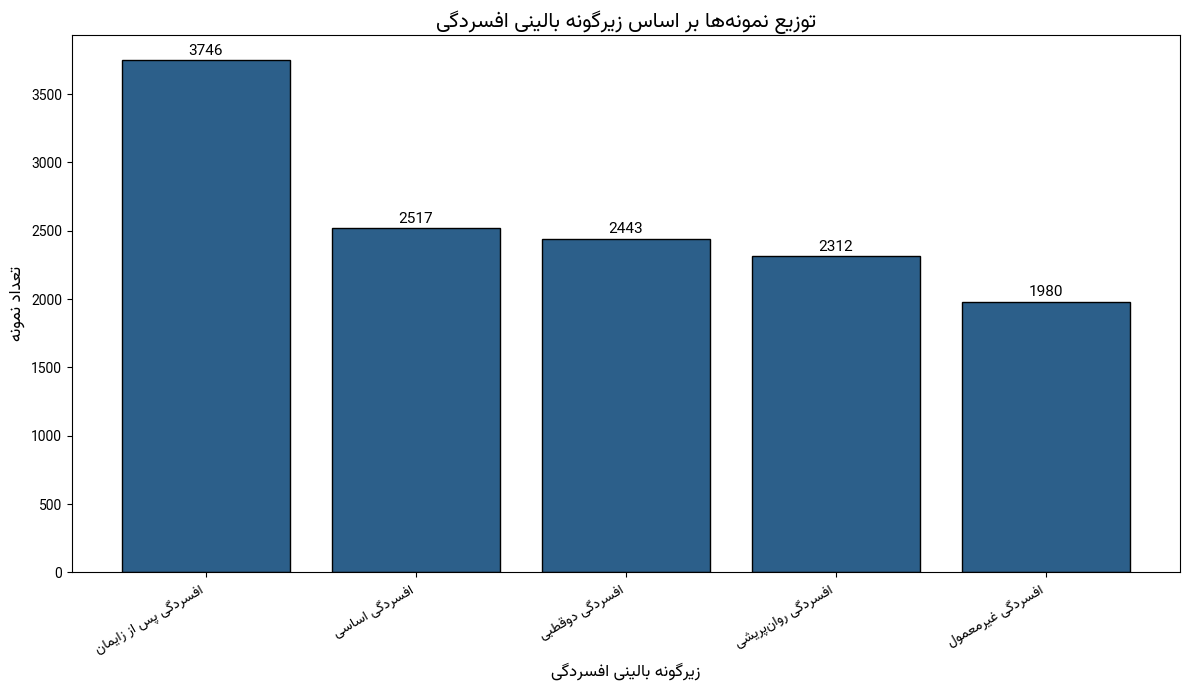

📊 [2/15] توزیع طول متن به تفکیک زیرگونه...


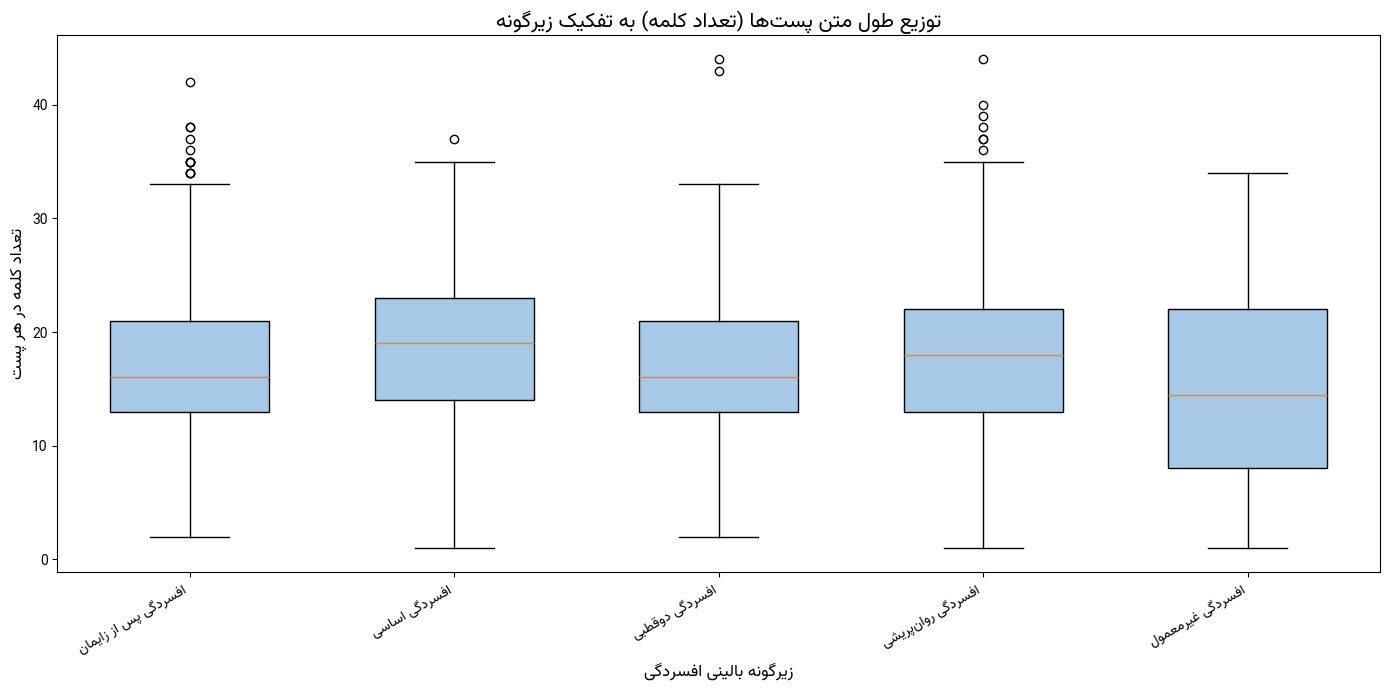

📊 [3/15] توزیع کلی طول پست‌ها...


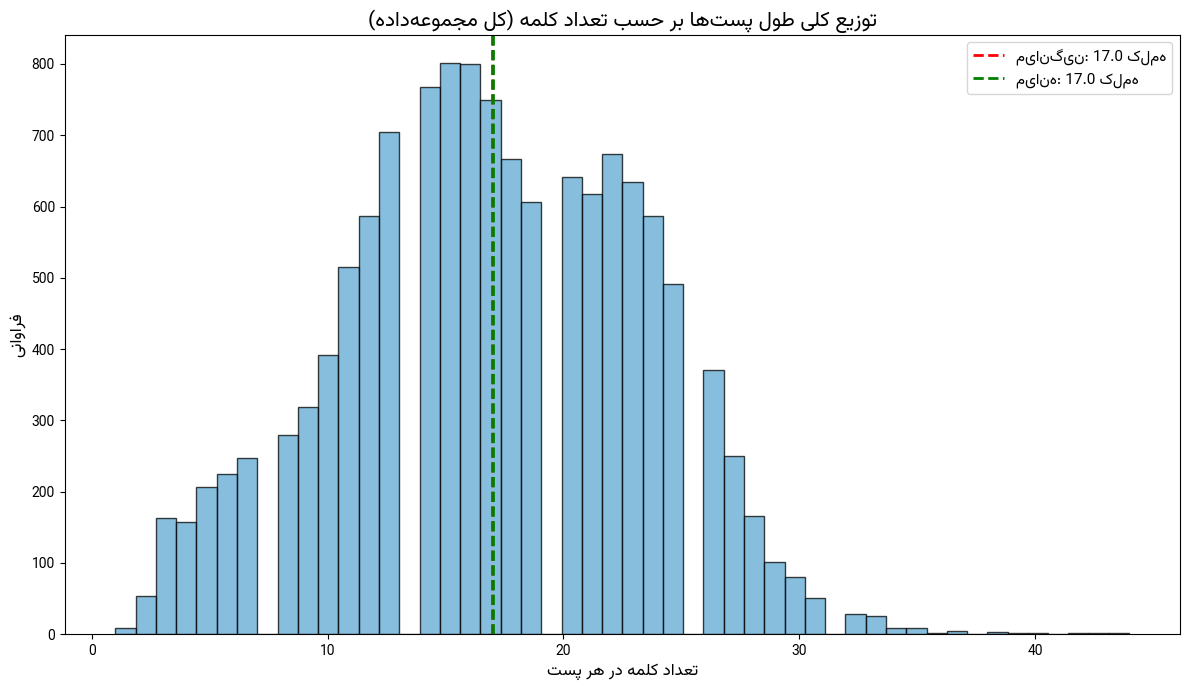

📊 [4/15] پرتکرارترین n-gram ها...


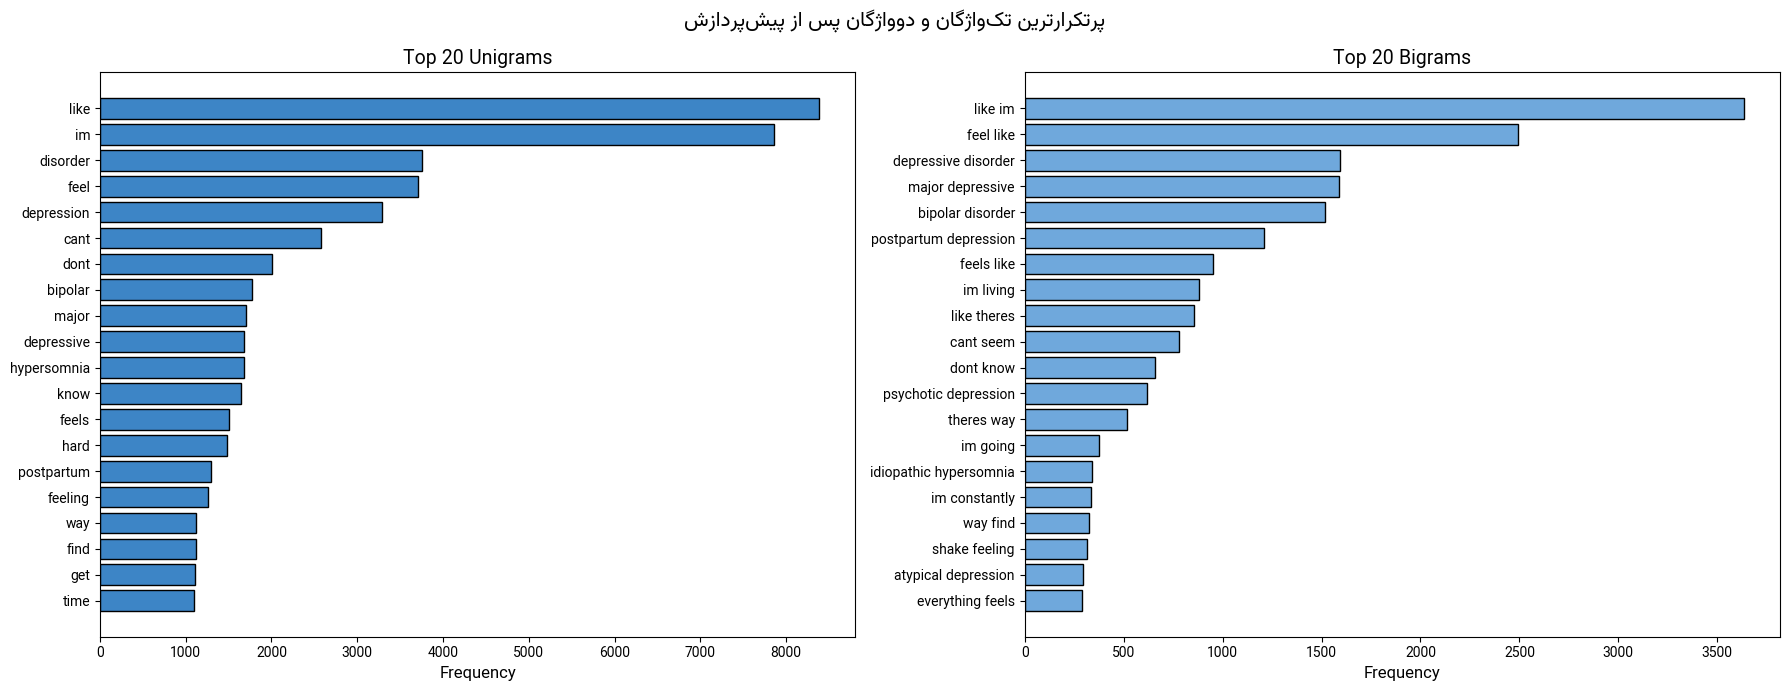

📊 [5/15] ابر واژگان هر زیرگونه...


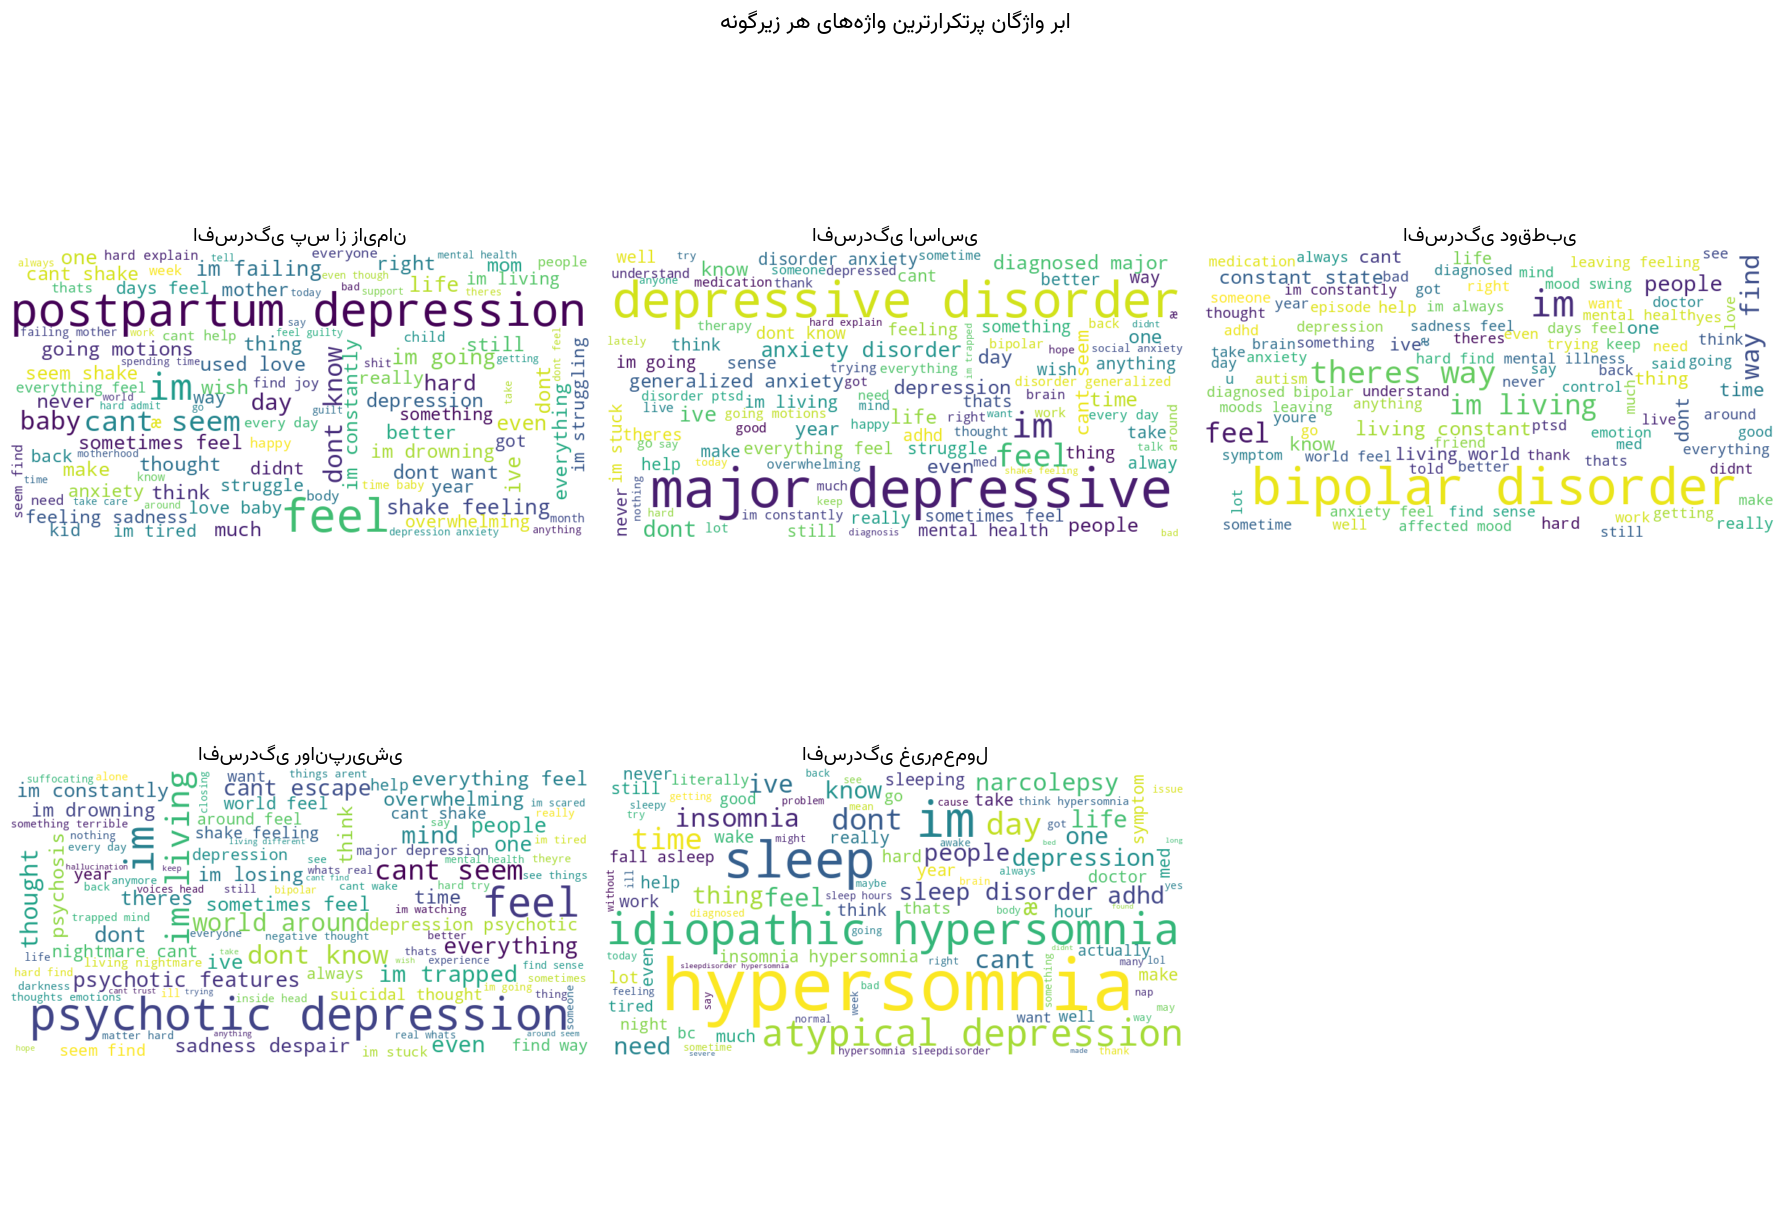

📊 [6/15] مقایسه عملکرد مدل‌ها...


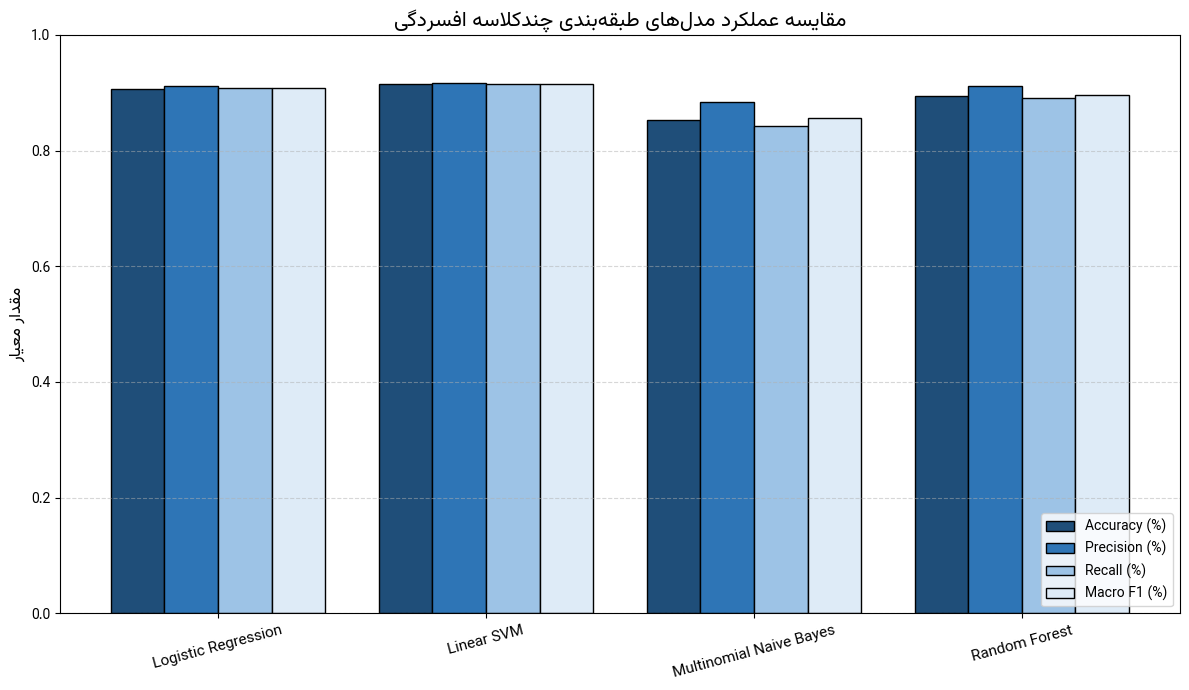

📊 [7/15] پایداری مدل‌ها با ۵-fold CV...
   Logistic Regression: 0.9070 ± 0.0057
   Linear SVM: 0.9152 ± 0.0056
   Multinomial Naive Bayes: 0.8473 ± 0.0047
   Random Forest: 0.8932 ± 0.0054


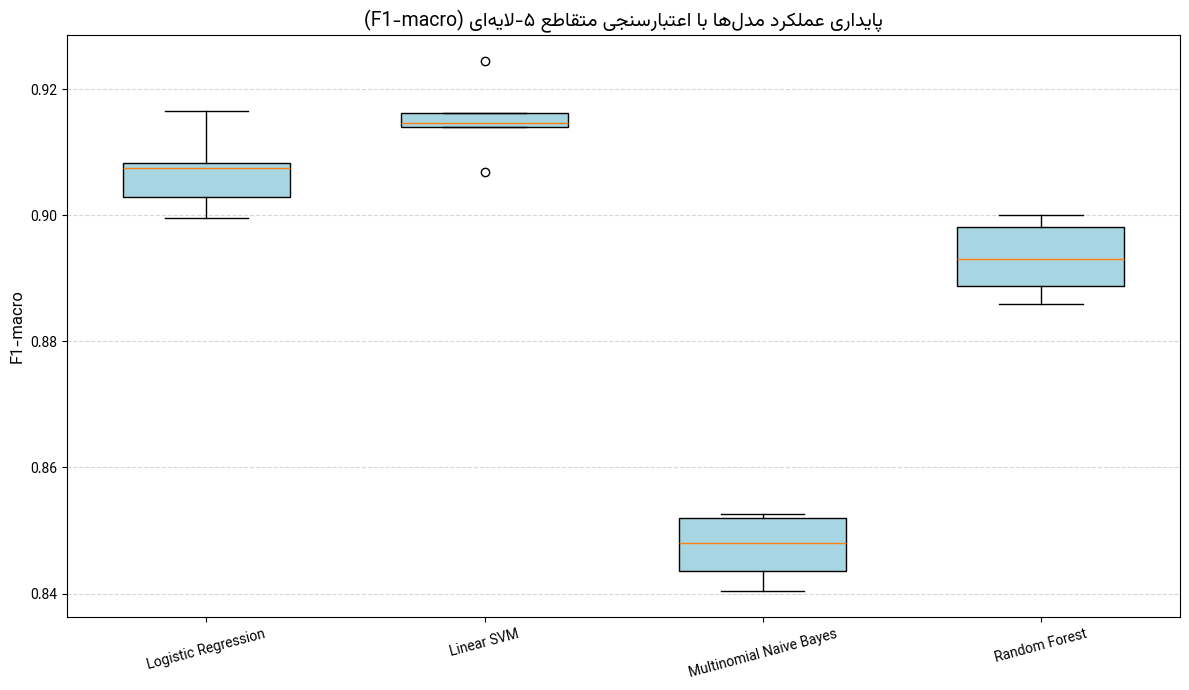

📊 [8/15] مقایسه زمان آموزش...


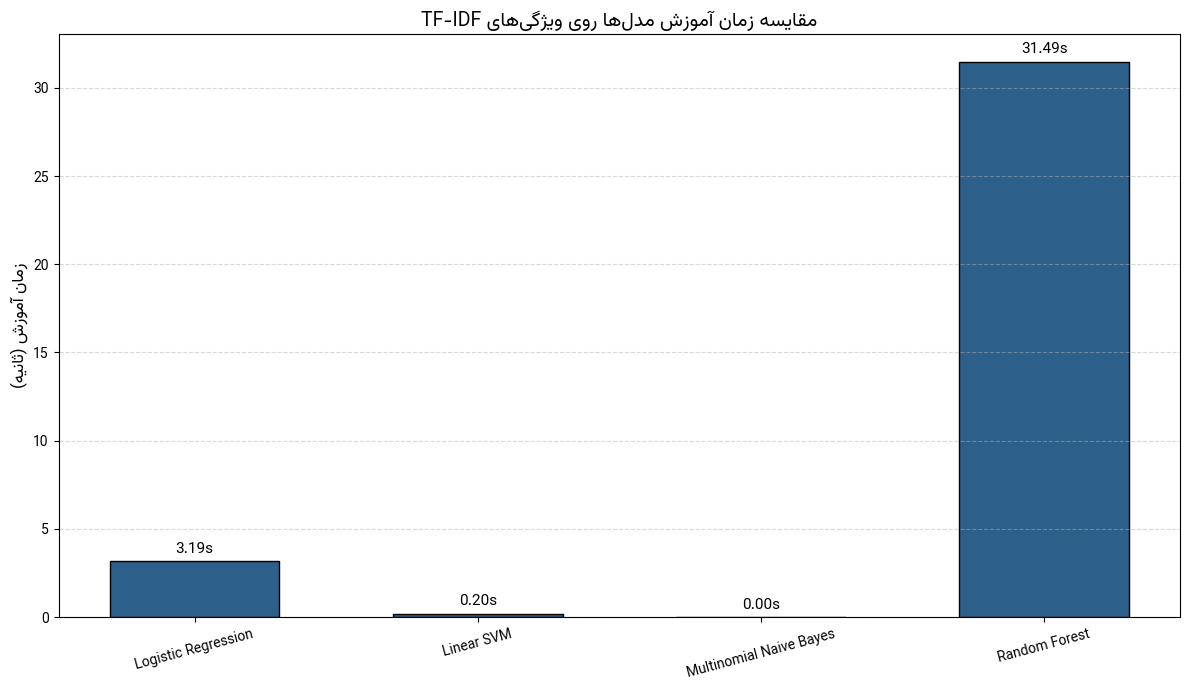

📊 [9/15] ماتریس درهم‌ریختگی Linear SVM...


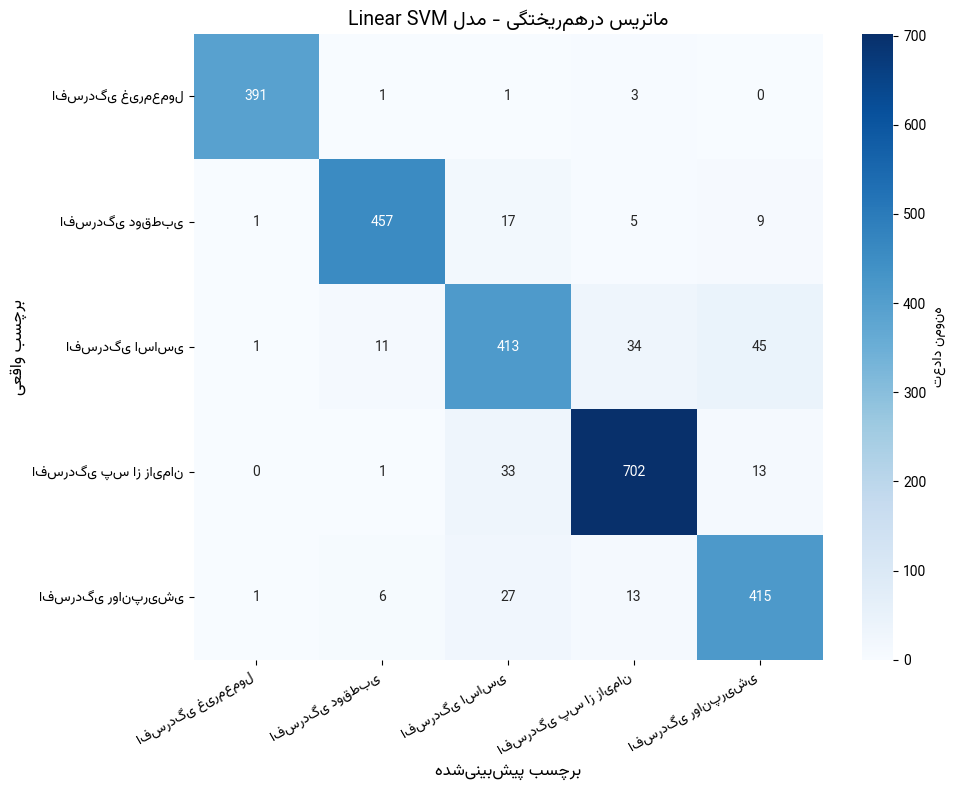

📊 [10/15] ماتریس نرمال‌شده...


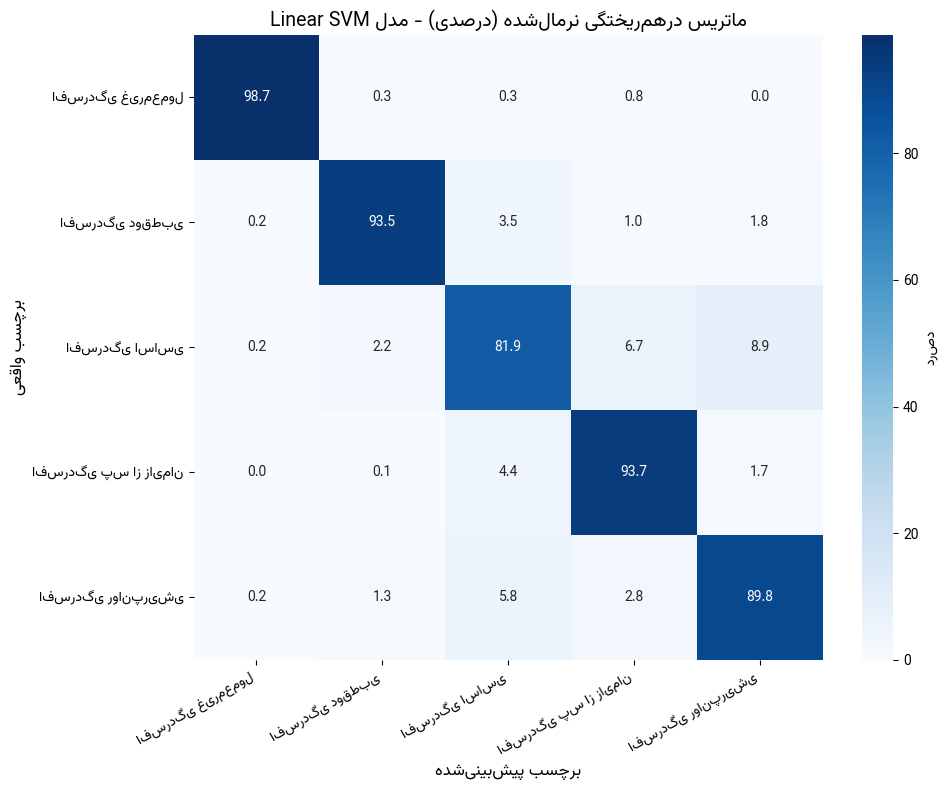

📊 [11/15] معیارها به تفکیک زیرگونه...


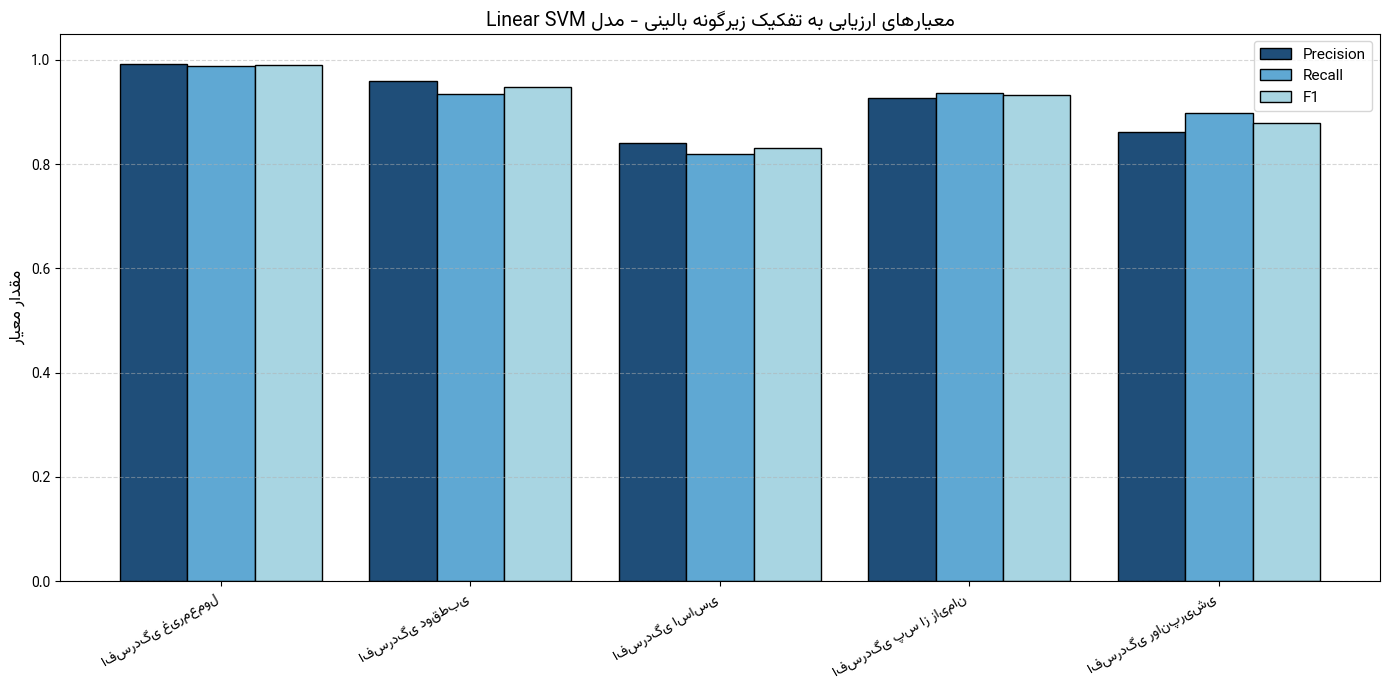

📊 [12/15] منحنی‌های ROC...


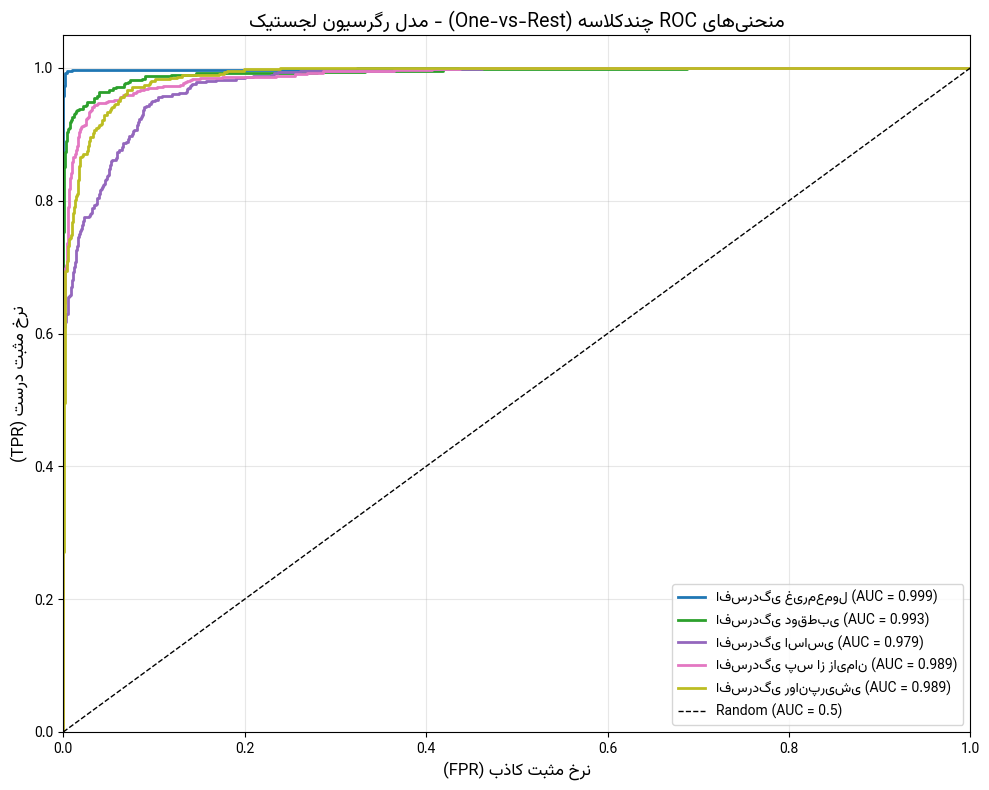

📊 [13/15] منحنی‌های Precision-Recall...


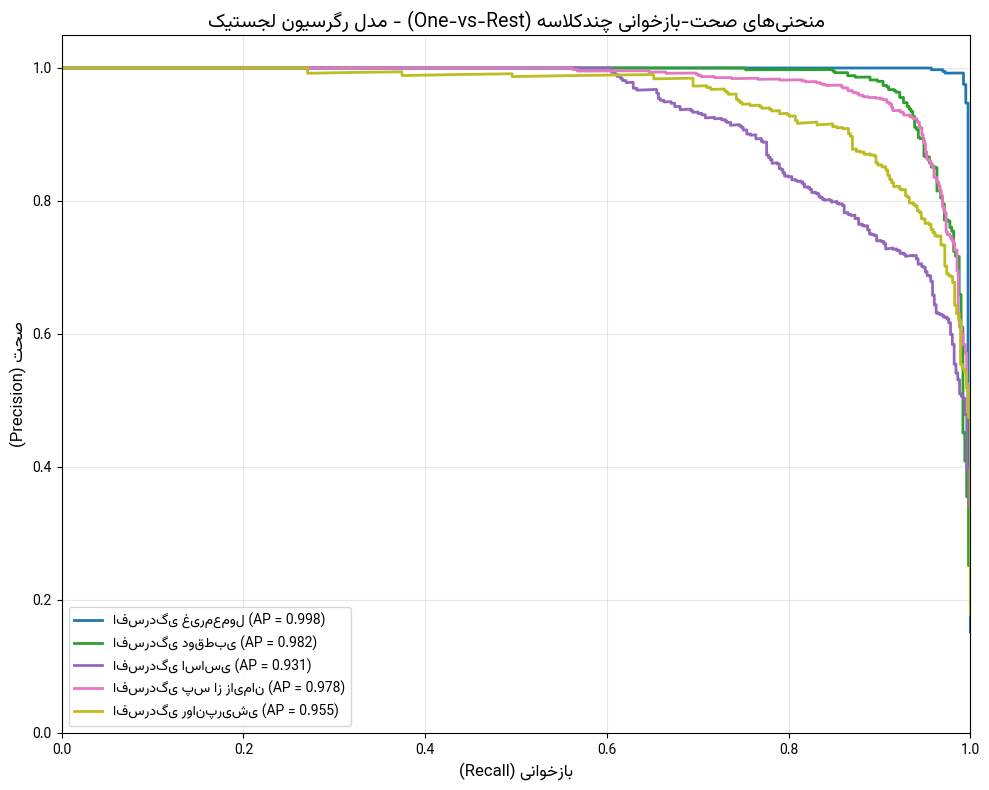

📊 [14/15] تصویرسازی دوبعدی TF-IDF...


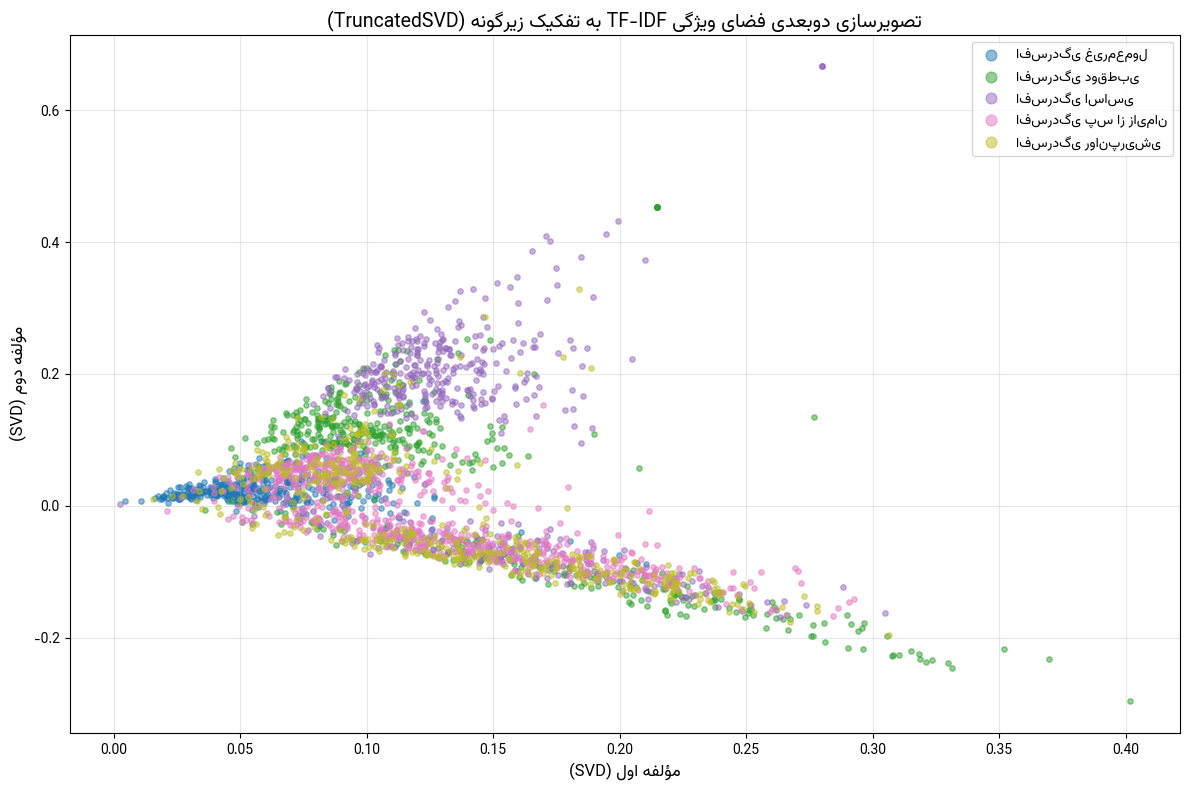

📊 [15/15] مهم‌ترین واژگان هر زیرگونه...


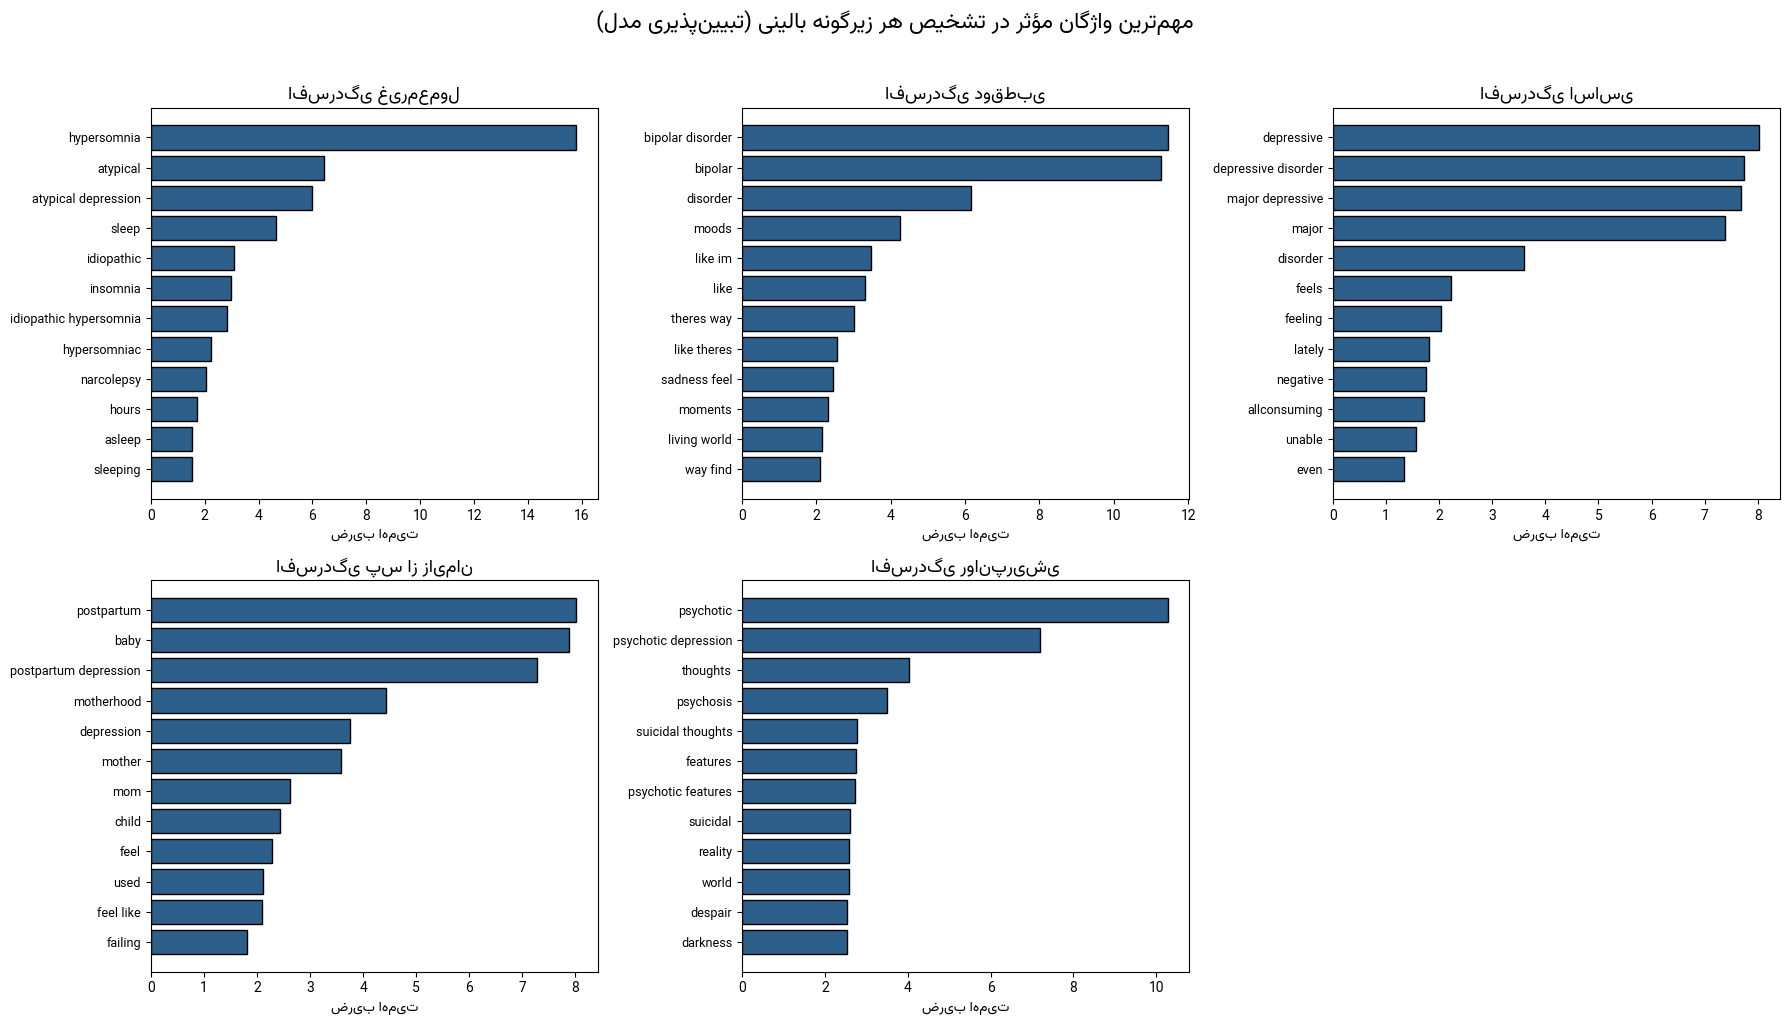


✅ همه‌ی ۱۵ نمودار با موفقیت رسم و ذخیره شدند!
📁 مسیر: /content/drive/MyDrive/nusrat_data/plots/svm_5class

📋 لیست فایل‌ها:
   ✅ fig_10_4_confusion_matrix_normalized.png (290.0 KB)
   ✅ fig_11_4_per_subtype_metrics.png (206.7 KB)
   ✅ fig_12_4_roc_curves.png (284.4 KB)
   ✅ fig_13_4_precision_recall_curves.png (250.4 KB)
   ✅ fig_14_4_tfidf_2d_visualization.png (1027.8 KB)
   ✅ fig_15_4_top_features_per_class.png (434.5 KB)
   ✅ fig_1_4_class_distribution.png (190.0 KB)
   ✅ fig_2_4_length_by_subtype.png (197.6 KB)
   ✅ fig_3_4_length_histogram.png (137.9 KB)
   ✅ fig_4_4_ngrams.png (287.3 KB)
   ✅ fig_5_4_wordclouds.png (4138.4 KB)
   ✅ fig_6_4_classifier_comparison.png (203.7 KB)
   ✅ fig_7_4_cv_stability.png (165.9 KB)
   ✅ fig_8_4_training_time.png (177.3 KB)
   ✅ fig_9_4_confusion_matrix.png (275.8 KB)

🏆 خلاصه نتایج Linear SVM (۵ کلاسه):
   Macro-F1:    91.57%
   Weighted-F1: 91.46%
   Accuracy:    91.46%


In [ ]:
# ============================================
# سلول ۳-ب: رسم ۱۵ نمودار برای SVM ۵ کلاسه
# ============================================
# پیش‌نیاز: سلول ۲ (بارگذاری باندل) قبلاً اجرا شده باشد

# --- ایمپورت‌ها ---
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize
import arabic_reshaper
from bidi.algorithm import get_display

# --- تابع کمکی برای نمایش صحیح متن فارسی ---
def fa(text):
    try:
        return get_display(arabic_reshaper.reshape(str(text)))
    except Exception:
        return str(text)

# --- نام‌های فارسی ۵ کلاس (بدون 'no') ---
FA_LABELS = {
    'atypical': 'افسردگی غیرمعمول',
    'bipolar': 'افسردگی دوقطبی',
    'major depressive': 'افسردگی اساسی',
    'postpartum': 'افسردگی پس از زایمان',
    'psychotic': 'افسردگی روان‌پریشی'
}

# --- تعداد کلاس‌ها ---
n_classes = len(label_encoder.classes_)
colors_roc = ['#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#bcbd22'][:n_classes]

print(f"📊 رسم نمودارها برای {n_classes} کلاس: {list(label_encoder.classes_)}")
print(f"📁 مسیر خروجی: {OUTPUT_DIR}")
print("=" * 70)


# ============================================
# نمودار ۱-۴: توزیع کلاس‌ها
# ============================================
print("📊 [1/15] توزیع کلاس‌ها...")
fig, ax = plt.subplots(figsize=(12, 7))
class_counts = df['Labels'].value_counts()
fa_names = [fa(FA_LABELS.get(name, name)) for name in class_counts.index]

bars = ax.bar(fa_names, class_counts.values, color='#2c5f8a', edgecolor='black')
for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            str(count), ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title(fa('توزیع نمونه‌ها بر اساس زیرگونه بالینی افسردگی'),
             fontsize=15, fontweight='bold')
ax.set_xlabel(fa('زیرگونه بالینی افسردگی'), fontsize=12)
ax.set_ylabel(fa('تعداد نمونه'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_1_4_class_distribution.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۲-۴: توزیع طول متن به تفکیک زیرگونه (Boxplot)
# ============================================
print("📊 [2/15] توزیع طول متن به تفکیک زیرگونه...")
df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(14, 7))
data_by_class = [df[df['Labels'] == cls]['word_count'].values for cls in class_counts.index]
bp = ax.boxplot(data_by_class,
                labels=[fa(FA_LABELS.get(c, c)) for c in class_counts.index],
                patch_artist=True, widths=0.6)

for patch in bp['boxes']:
    patch.set_facecolor('#a8c8e8')
    patch.set_edgecolor('black')

ax.set_title(fa('توزیع طول متن پست‌ها (تعداد کلمه) به تفکیک زیرگونه'),
             fontsize=15, fontweight='bold')
ax.set_xlabel(fa('زیرگونه بالینی افسردگی'), fontsize=12)
ax.set_ylabel(fa('تعداد کلمه در هر پست'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_2_4_length_by_subtype.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۳-۴: توزیع کلی طول پست‌ها
# ============================================
print("📊 [3/15] توزیع کلی طول پست‌ها...")
fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(df['word_count'], bins=50, color='#5fa8d3', edgecolor='black', alpha=0.75)
ax.axvline(df['word_count'].mean(), color='red', linestyle='--', linewidth=2,
           label=f"میانگین: {df['word_count'].mean():.1f} کلمه")
ax.axvline(df['word_count'].median(), color='green', linestyle='--', linewidth=2,
           label=f"میانه: {df['word_count'].median():.1f} کلمه")

ax.set_title(fa('توزیع کلی طول پست‌ها بر حسب تعداد کلمه (کل مجموعه‌داده)'),
             fontsize=15, fontweight='bold')
ax.set_xlabel(fa('تعداد کلمه در هر پست'), fontsize=12)
ax.set_ylabel(fa('فراوانی'), fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_3_4_length_histogram.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۴-۴: پرتکرارترین n-gram ها
# ============================================
print("📊 [4/15] پرتکرارترین n-gram ها...")
all_words = ' '.join(df['clean_text']).split()
unigram_counts = Counter(all_words).most_common(20)

bigrams = []
for text in df['clean_text']:
    words = text.split()
    bigrams.extend([' '.join(words[i:i+2]) for i in range(len(words)-1)])
bigram_counts = Counter(bigrams).most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

words_uni, counts_uni = zip(*unigram_counts)
axes[0].barh(list(reversed(words_uni)), list(reversed(counts_uni)),
             color='#3d85c6', edgecolor='black')
axes[0].set_title('Top 20 Unigrams', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Frequency', fontsize=12)

words_bi, counts_bi = zip(*bigram_counts)
axes[1].barh(list(reversed(words_bi)), list(reversed(counts_bi)),
             color='#6fa8dc', edgecolor='black')
axes[1].set_title('Top 20 Bigrams', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency', fontsize=12)

plt.suptitle(fa('پرتکرارترین تک‌واژگان و دوواژگان پس از پیش‌پردازش'),
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_4_4_ngrams.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۵-۴: ابر واژگان هر زیرگونه
# ============================================
print("📊 [5/15] ابر واژگان هر زیرگونه...")
n_cols = 3
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 6 * n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

for i, cls in enumerate(class_counts.index):
    text = ' '.join(df[df['Labels'] == cls]['clean_text'])
    if len(text.strip()) > 0:
        wc = WordCloud(width=800, height=400, background_color='white',
                       colormap='viridis', max_words=100).generate(text)
        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(FA_LABELS.get(cls, cls), fontsize=14, fontweight='bold')
        axes[i].axis('off')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(fa('ابر واژگان پرتکرارترین واژه‌های هر زیرگونه'),
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_5_4_wordclouds.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۶-۴: مقایسه عملکرد مدل‌ها
# ============================================
print("📊 [6/15] مقایسه عملکرد مدل‌ها...")
fig, ax = plt.subplots(figsize=(12, 7))
metrics_plot = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'Macro F1 (%)']
x = np.arange(len(results_df.index))
width = 0.20
colors_bar = ['#1f4e79', '#2e75b6', '#9dc3e6', '#deebf7']

for i, metric in enumerate(metrics_plot):
    ax.bar(x + i * width, results_df[metric].values / 100, width,
           label=metric, color=colors_bar[i], edgecolor='black')

ax.set_title(fa('مقایسه عملکرد مدل‌های طبقه‌بندی چندکلاسه افسردگی'),
             fontsize=15, fontweight='bold')
ax.set_ylabel(fa('مقدار معیار'), fontsize=12)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(results_df.index, rotation=15, fontsize=11)
ax.set_ylim(0, 1.0)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_6_4_classifier_comparison.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۷-۴: پایداری با ۵-fold CV
# ============================================
print("📊 [7/15] پایداری مدل‌ها با ۵-fold CV...")
cv_results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in classifiers.items():
    scores = cross_val_score(clf, X_train_tfidf, y_train, cv=skf,
                             scoring='f1_macro', n_jobs=-1)
    cv_results[name] = scores
    print(f"   {name}: {scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(12, 7))
bp = ax.boxplot(list(cv_results.values()),
                labels=list(cv_results.keys()),
                patch_artist=True, widths=0.6)
for patch in bp['boxes']:
    patch.set_facecolor('#a8d5e2')
    patch.set_edgecolor('black')

ax.set_title(fa('پایداری عملکرد مدل‌ها با اعتبارسنجی متقاطع ۵-لایه‌ای (F1-macro)'),
             fontsize=14, fontweight='bold')
ax.set_ylabel('F1-macro', fontsize=12)
plt.xticks(rotation=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_7_4_cv_stability.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۸-۴: زمان آموزش
# ============================================
print("📊 [8/15] مقایسه زمان آموزش...")
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(training_times.keys(), training_times.values(),
              color='#2c5f8a', edgecolor='black', width=0.6)
for bar, t in zip(bars, training_times.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f'{t:.2f}s', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title(fa('مقایسه زمان آموزش مدل‌ها روی ویژگی‌های TF-IDF'),
             fontsize=14, fontweight='bold')
ax.set_ylabel(fa('زمان آموزش (ثانیه)'), fontsize=12)
plt.xticks(rotation=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_8_4_training_time.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۹-۴: ماتریس درهم‌ریختگی Linear SVM
# ============================================
print("📊 [9/15] ماتریس درهم‌ریختگی Linear SVM...")
best_model = classifiers['Linear SVM']
y_pred_best = best_model.predict(X_test_tfidf)
cm = confusion_matrix(y_test, y_pred_best)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[FA_LABELS.get(c, c) for c in label_encoder.classes_],
            yticklabels=[FA_LABELS.get(c, c) for c in label_encoder.classes_],
            ax=ax, cbar_kws={'label': 'تعداد نمونه'})
ax.set_title(fa('ماتریس درهم‌ریختگی - مدل Linear SVM'),
             fontsize=14, fontweight='bold')
ax.set_xlabel(fa('برچسب پیش‌بینی‌شده'), fontsize=12)
ax.set_ylabel(fa('برچسب واقعی'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_9_4_confusion_matrix.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۰-۴: ماتریس نرمال‌شده
# ============================================
print("📊 [10/15] ماتریس نرمال‌شده...")
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=[FA_LABELS.get(c, c) for c in label_encoder.classes_],
            yticklabels=[FA_LABELS.get(c, c) for c in label_encoder.classes_],
            ax=ax, cbar_kws={'label': 'درصد'})
ax.set_title(fa('ماتریس درهم‌ریختگی نرمال‌شده (درصدی) - مدل Linear SVM'),
             fontsize=14, fontweight='bold')
ax.set_xlabel(fa('برچسب پیش‌بینی‌شده'), fontsize=12)
ax.set_ylabel(fa('برچسب واقعی'), fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_10_4_confusion_matrix_normalized.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۱-۴: معیارها به تفکیک زیرگونه
# ============================================
print("📊 [11/15] معیارها به تفکیک زیرگونه...")
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred_best, average=None, zero_division=0
)

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(label_encoder.classes_))
width = 0.27

ax.bar(x - width, precision, width, label='Precision', color='#1f4e79', edgecolor='black')
ax.bar(x, recall, width, label='Recall', color='#5fa8d3', edgecolor='black')
ax.bar(x + width, f1, width, label='F1', color='#a8d5e2', edgecolor='black')

ax.set_title(fa('معیارهای ارزیابی به تفکیک زیرگونه بالینی - مدل Linear SVM'),
             fontsize=14, fontweight='bold')
ax.set_ylabel(fa('مقدار معیار'), fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels([FA_LABELS.get(c, c) for c in label_encoder.classes_],
                   rotation=30, ha='right')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_11_4_per_subtype_metrics.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۲-۴: منحنی‌های ROC
# ============================================
print("📊 [12/15] منحنی‌های ROC...")
clf_lr = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
clf_lr.fit(X_train_tfidf, y_train)
y_score = clf_lr.predict_proba(X_test_tfidf)

y_test_bin = label_binarize(y_test, classes=range(n_classes))

fig, ax = plt.subplots(figsize=(10, 8))
for i, color in zip(range(n_classes), colors_roc):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    label_name = FA_LABELS.get(label_encoder.classes_[i], label_encoder.classes_[i])
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f'{label_name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.5)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel(fa('نرخ مثبت کاذب (FPR)'), fontsize=12)
ax.set_ylabel(fa('نرخ مثبت درست (TPR)'), fontsize=12)
ax.set_title(fa('منحنی‌های ROC چندکلاسه (One-vs-Rest) - مدل رگرسیون لجستیک'),
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_12_4_roc_curves.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۳-۴: Precision-Recall
# ============================================
print("📊 [13/15] منحنی‌های Precision-Recall...")
fig, ax = plt.subplots(figsize=(10, 8))
for i, color in zip(range(n_classes), colors_roc):
    p_curve, r_curve, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_score[:, i])
    label_name = FA_LABELS.get(label_encoder.classes_[i], label_encoder.classes_[i])
    ax.plot(r_curve, p_curve, color=color, lw=2,
            label=f'{label_name} (AP = {ap:.3f})')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel(fa('بازخوانی (Recall)'), fontsize=12)
ax.set_ylabel(fa('صحت (Precision)'), fontsize=12)
ax.set_title(fa('منحنی‌های صحت-بازخوانی چندکلاسه (One-vs-Rest) - مدل رگرسیون لجستیک'),
             fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_13_4_precision_recall_curves.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۴-۴: تصویرسازی دوبعدی با SVD
# ============================================
print("📊 [14/15] تصویرسازی دوبعدی TF-IDF...")
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_test_tfidf)

fig, ax = plt.subplots(figsize=(12, 8))
for i, cls in enumerate(label_encoder.classes_):
    mask = y_test == i
    label_name = FA_LABELS.get(cls, cls)
    ax.scatter(X_svd[mask, 0], X_svd[mask, 1],
               c=colors_roc[i], label=label_name, alpha=0.5, s=15)

ax.set_xlabel(fa('مؤلفه اول (SVD)'), fontsize=12)
ax.set_ylabel(fa('مؤلفه دوم (SVD)'), fontsize=12)
ax.set_title(fa('تصویرسازی دوبعدی فضای ویژگی TF-IDF به تفکیک زیرگونه (TruncatedSVD)'),
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10, markerscale=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_14_4_tfidf_2d_visualization.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# نمودار ۱۵-۴: مهم‌ترین واژگان هر زیرگونه
# ============================================
print("📊 [15/15] مهم‌ترین واژگان هر زیرگونه...")
best_clf_for_features = LogisticRegression(
    max_iter=2000, class_weight='balanced', random_state=42
)
best_clf_for_features.fit(X_train_tfidf, y_train)

feature_names = vectorizer.get_feature_names_out()
coef_matrix = best_clf_for_features.coef_

n_cols_plot = 3
n_rows_plot = (n_classes + n_cols_plot - 1) // n_cols_plot
fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(18, 5 * n_rows_plot))
axes = axes.flatten()

for i, cls in enumerate(label_encoder.classes_):
    top_indices = np.argsort(coef_matrix[i])[-12:][::-1]
    top_words = [feature_names[idx] for idx in top_indices]
    top_scores = [coef_matrix[i][idx] for idx in top_indices]

    axes[i].barh(list(reversed(top_words)), list(reversed(top_scores)),
                 color='#2c5f8a', edgecolor='black')
    axes[i].set_title(FA_LABELS.get(cls, cls), fontsize=13, fontweight='bold')
    axes[i].set_xlabel('ضریب اهمیت', fontsize=10)
    axes[i].tick_params(axis='y', labelsize=9)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(fa('مهم‌ترین واژگان مؤثر در تشخیص هر زیرگونه بالینی (تبیین‌پذیری مدل)'),
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "fig_15_4_top_features_per_class.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


# ============================================
# گزارش نهایی
# ============================================
print("\n" + "=" * 80)
print("✅ همه‌ی ۱۵ نمودار با موفقیت رسم و ذخیره شدند!")
print("=" * 80)
print(f"📁 مسیر: {OUTPUT_DIR}")
print(f"\n📋 لیست فایل‌ها:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(OUTPUT_DIR / f) / 1024
    print(f"   ✅ {f} ({size:.1f} KB)")

print("\n🏆 خلاصه نتایج Linear SVM (۵ کلاسه):")
print(f"   Macro-F1:    {results['Linear SVM']['F1-Score']:.2f}%")
print(f"   Weighted-F1: {results['Linear SVM']['Weighted-F1']:.2f}%")
print(f"   Accuracy:    {results['Linear SVM']['Accuracy']:.2f}%")

In [ ]:
# ============================================
# XAI برای SVM ۵ کلاسه
# شامل: SHAP + LIME + Feature Coefficients
# ============================================

# --- نصب کتابخانه‌ها ---
%pip install shap lime -q

import os, re, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

warnings.filterwarnings('ignore')

# --- اتصال Drive ---
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_BASE = Path("/content/drive/MyDrive/nusrat_data")
BUNDLE_PATH = DRIVE_BASE / "models" / "svm_5class" / "svm_bundle.pkl"
XAI_DIR = DRIVE_BASE / "plots" / "xai_svm"
SHAP_DIR = XAI_DIR / "shap"
LIME_DIR = XAI_DIR / "lime"
FEAT_DIR = XAI_DIR / "features"
for d in [SHAP_DIR, LIME_DIR, FEAT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# --- بارگذاری باندل ---
with open(BUNDLE_PATH, 'rb') as f:
    bundle = pickle.load(f)

df = bundle['df']
classifiers = bundle['classifiers']
vectorizer = bundle['vectorizer']
label_encoder = bundle['label_encoder']
results_df = bundle['results_df']
X_train_tfidf = bundle['X_train_tfidf']
X_test_tfidf = bundle['X_test_tfidf']
y_train = bundle['y_train']
y_test = bundle['y_test']

n_classes = len(label_encoder.classes_)
class_names = list(label_encoder.classes_)

print(f"✅ باندل بارگذاری شد. تعداد کلاس‌ها: {n_classes}")
print(f"   کلاس‌ها: {class_names}")

# --- تابع پاکسازی متن (معادل سلول ۱) ---
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = ' '.join([w for w in text.split() if w not in stop_words])
    return text.strip()


# ============================================
# بخش ۱: SHAP برای SVM (LinearExplainer)
# ============================================
print("\n" + "=" * 70)
print("🔍 بخش ۱: SHAP (LinearExplainer)")
print("=" * 70)

import shap

svm_model = classifiers['Linear SVM']

# SHAP LinearExplainer برای مدل‌های خطی (سریع و دقیق)
try:
    explainer_shap = shap.LinearExplainer(
        svm_model, X_train_tfidf,
        feature_perturbation="interventional"
    )
    print("✅ LinearExplainer ساخته شد.")
except Exception as e:
    print(f"⚠️ LinearExplainer خطا داد: {e}")
    print("   تلاش با KernelExplainer (کندتر)...")
    explainer_shap = None

# نمونه‌گیری ۱۰۰ نمونه از تست برای تحلیل SHAP
np.random.seed(42)
sample_size = min(100, X_test_tfidf.shape[0])
sample_idx = np.random.choice(X_test_tfidf.shape[0], sample_size, replace=False)
X_sample = X_test_tfidf[sample_idx]
y_sample = y_test[sample_idx]

print(f"⏳ محاسبه SHAP روی {sample_size} نمونه...")

try:
    shap_values = explainer_shap(X_sample)
    # shap_values.values برای multi-class: shape = (n_samples, n_features, n_classes)
    sv = shap_values.values
    print(f"✅ SHAP محاسبه شد. Shape: {sv.shape}")

    # --- Plot 1: Summary Bar per class ---
    for cls_id, cls_name in enumerate(class_names):
        plt.figure(figsize=(10, 6))
        # میانگین قدرمطلق SHAP برای هر ویژگی، برای کلاس cls_id
        mean_abs_shap = np.abs(sv[:, :, cls_id]).mean(axis=0)
        top_idx = np.argsort(mean_abs_shap)[-20:][::-1]
        feature_names = vectorizer.get_feature_names_out()
        top_features = [feature_names[i] for i in top_idx]
        top_values = mean_abs_shap[top_idx]

        plt.barh(list(reversed(top_features)), list(reversed(top_values)),
                 color='#2c5f8a', edgecolor='black')
        plt.title(f"Top 20 SHAP Features — {cls_name}", fontsize=13, fontweight='bold')
        plt.xlabel("Mean |SHAP value|", fontsize=11)
        plt.tight_layout()
        plt.savefig(str(SHAP_DIR / f"shap_summary_{cls_name}.png"),
                    dpi=200, bbox_inches='tight')
        plt.close()
        print(f"   ✅ SHAP summary for {cls_name}")

    # --- Plot 2: Global summary ---
    plt.figure(figsize=(10, 8))
    global_imp = np.abs(sv).mean(axis=(0, 2))  # میانگین روی نمونه‌ها و کلاس‌ها
    top_idx = np.argsort(global_imp)[-20:][::-1]
    feature_names = vectorizer.get_feature_names_out()
    top_features = [feature_names[i] for i in top_idx]
    top_values = global_imp[top_idx]

    plt.barh(list(reversed(top_features)), list(reversed(top_values)),
             color='#55A868', edgecolor='black')
    plt.title("Top 20 Global SHAP Features (All Classes)", fontsize=13, fontweight='bold')
    plt.xlabel("Mean |SHAP value|", fontsize=11)
    plt.tight_layout()
    plt.savefig(str(SHAP_DIR / "shap_global_summary.png"),
                dpi=200, bbox_inches='tight')
    plt.close()
    print("   ✅ SHAP global summary")
    print(f"✅ نمودارهای SHAP ذخیره شدند: {SHAP_DIR}")

except Exception as e:
    print(f"⚠️ خطا در SHAP: {e}")
    print("   بخش SHAP رد شد.")


# ============================================
# بخش ۲: LIME برای SVM
# ============================================
print("\n" + "=" * 70)
print("🔍 بخش ۲: LIME")
print("=" * 70)

from lime.lime_text import LimeTextExplainer

# --- تابع predict_proba برای SVM ---
# LinearSVC فاقد predict_proba است. از decision_function + softmax استفاده می‌کنیم.
def predict_proba_svm(texts):
    """ورودی: لیست متن؛ خروجی: احتمال ۵ کلاس"""
    cleaned = [clean_text(t) for t in texts]
    X = vectorizer.transform(cleaned)
    decision = svm_model.decision_function(X)
    # Softmax برای تبدیل decision به احتمال
    exp_d = np.exp(decision - decision.max(axis=1, keepdims=True))
    return exp_d / exp_d.sum(axis=1, keepdims=True)


lime_explainer = LimeTextExplainer(class_names=class_names)

# --- انتخاب نمونه‌ها (۲ نمونه از هر کلاس = ۱۰ نمونه) ---
test_df = pd.DataFrame({
    'text': bundle['X_test'],
    'labels': y_test
})

sample_texts, sample_true_labels, sample_true_ids = [], [], []
for cls_id, cls_name in enumerate(class_names):
    cls_examples = test_df[test_df['labels'] == cls_id]['text'].head(2).tolist()
    sample_texts.extend(cls_examples)
    sample_true_labels.extend([cls_name] * len(cls_examples))
    sample_true_ids.extend([cls_id] * len(cls_examples))

print(f"⏳ اجرای LIME روی {len(sample_texts)} نمونه...")

# --- ذخیره‌ی نتایج در CSV (علاوه بر HTML) ---
lime_results_csv = []

for idx, (text, true_label, true_id) in enumerate(zip(sample_texts, sample_true_labels, sample_true_ids)):
    try:
        exp = lime_explainer.explain_instance(
            text, predict_proba_svm,
            num_features=10, num_samples=500,
            labels=[true_id]
        )

        # ذخیره HTML
        save_html = LIME_DIR / f"lime_example_{idx}_{true_label}.html"
        exp.save_to_file(str(save_html))

        # ذخیره در CSV
        for word, weight in exp.as_list(label=true_id):
            lime_results_csv.append({
                'sample_id': idx,
                'true_label': true_label,
                'word': word,
                'weight': weight,
            })

        print(f"   ✅ [{idx+1}/10] {true_label} → {save_html.name}")
    except Exception as e:
        print(f"   ⚠️ خطا در نمونه {idx}: {e}")

# ذخیره CSV
if lime_results_csv:
    lime_df = pd.DataFrame(lime_results_csv)
    lime_df.to_csv(str(LIME_DIR / "lime_results.csv"), index=False)
    print(f"\n✅ LIME CSV ذخیره شد: {LIME_DIR / 'lime_results.csv'}")

# --- نمودار خلاصه‌ی LIME ---
if lime_results_csv:
    # میانگین |weight| هر کلمه در همه‌ی نمونه‌ها
    word_imp = lime_df.groupby('word')['weight'].apply(lambda x: np.abs(x).mean())
    top20 = word_imp.sort_values(ascending=False).head(20)

    plt.figure(figsize=(10, 7))
    plt.barh(list(reversed(top20.index)), list(reversed(top20.values)),
             color='#C44E52', edgecolor='black')
    plt.title("Top 20 LIME Words (Mean |Weight|)", fontsize=13, fontweight='bold')
    plt.xlabel("Mean |Weight|", fontsize=11)
    plt.tight_layout()
    plt.savefig(str(LIME_DIR / "lime_summary.png"), dpi=200, bbox_inches='tight')
    plt.close()
    print(f"✅ نمودار LIME summary ذخیره شد.")


# ============================================
# بخش ۳: Feature Coefficients (جایگزین Attention برای SVM)
# ============================================
print("\n" + "=" * 70)
print("🔍 بخش ۳: Feature Coefficients (معادل Attention برای مدل خطی)")
print("=" * 70)

feature_names = vectorizer.get_feature_names_out()
coef_matrix = svm_model.coef_  # shape = (n_classes, n_features)

print(f"   Shape of coefficients: {coef_matrix.shape}")

# --- Plot 1: Heatmap از Top 30 features × 5 classes ---
# میانگین قدرمطلق ضرایب برای انتخاب برترین‌ها
mean_abs_coef = np.abs(coef_matrix).mean(axis=0)
top30_idx = np.argsort(mean_abs_coef)[-30:][::-1]
top30_features = [feature_names[i] for i in top30_idx]
top30_coef = coef_matrix[:, top30_idx].T  # (30, n_classes)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(top30_coef, annot=False, cmap='RdBu_r',
            xticklabels=class_names, yticklabels=top30_features,
            center=0, cbar_kws={'label': 'Coefficient'}, ax=ax)
ax.set_title("Top 30 Features × Classes — SVM Coefficients",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Class", fontsize=11)
ax.set_ylabel("Feature (word/bigram)", fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(FEAT_DIR / "coefficient_heatmap.png"), dpi=200, bbox_inches='tight')
plt.close()
print("   ✅ Heatmap ضرایب ذخیره شد.")

# --- Plot 2: Top 15 features per class (bar charts) ---
n_cols = 3
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, cls_name in enumerate(class_names):
    top_idx = np.argsort(coef_matrix[i])[-15:][::-1]
    top_features = [feature_names[j] for j in top_idx]
    top_scores = [coef_matrix[i][j] for j in top_idx]

    axes[i].barh(list(reversed(top_features)), list(reversed(top_scores)),
                 color='#2c5f8a', edgecolor='black')
    axes[i].set_title(f"Top Features — {cls_name}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Coefficient", fontsize=10)
    axes[i].tick_params(axis='y', labelsize=9)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Top 15 Features per Class — SVM Coefficients",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FEAT_DIR / "coefficients_per_class.png"),
            dpi=200, bbox_inches='tight')
plt.close()
print("   ✅ Per-class bar charts ذخیره شد.")

# --- Plot 3: ذخیره CSV از ضرایب برای گزارش‌گیری ---
coef_df = pd.DataFrame(coef_matrix.T, index=feature_names, columns=class_names)
# ذخیره فقط top 100 features
top100_idx = np.argsort(mean_abs_coef)[-100:][::-1]
coef_df.iloc[top100_idx].to_csv(str(FEAT_DIR / "top100_coefficients.csv"))
print("   ✅ CSV ضرایب ذخیره شد.")


# ============================================
# گزارش نهایی
# ============================================
print("\n" + "=" * 80)
print("✅ XAI برای SVM کامل شد!")
print("=" * 80)
print(f"\n📁 پوشه‌ها:")
print(f"   ├── SHAP:    {SHAP_DIR}")
print(f"   ├── LIME:    {LIME_DIR}")
print(f"   └── Features: {FEAT_DIR}")

print("\n📋 لیست فایل‌ها:")
for folder, label in [(SHAP_DIR, 'SHAP'), (LIME_DIR, 'LIME'), (FEAT_DIR, 'Features')]:
    files = sorted(os.listdir(folder))
    print(f"\n   {label}:")
    for f in files:
        size = os.path.getsize(folder / f) / 1024
        print(f"      ✅ {f} ({size:.1f} KB)")

# ============================================
# خلاصه‌ی نتایج
# ============================================
print("\n" + "=" * 80)
print("📊 خلاصه")
print("=" * 80)
print(f"   SVM Macro-F1 (از باندل): {results_df.loc['Linear SVM', 'Macro F1 (%)']:.2f}%")
print(f"   تعداد نمونه‌های SHAP: {sample_size}")
print(f"   تعداد نمونه‌های LIME: {len(sample_texts)}")
print(f"   تعداد features: {len(feature_names)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Mounted at /content/drive
✅ باندل بارگذاری شد. تعداد کلاس‌ها: 5
   کلاس‌ها: ['atypical', 'bipolar', 'major depressive', 'postpartum', 'psychotic']

🔍 بخش ۱: SHAP (LinearExplainer)


✅ LinearExplainer ساخته شد.
⏳ محاسبه SHAP روی 100 نمونه...
✅ SHAP محاسبه شد. Shape: (100, 20577, 5)
   ✅ SHAP summary for atypical
   ✅ SHAP summary for bipolar
   ✅ SHAP summary for major depressive
   ✅ SHAP summary for postpartum
   ✅ SHAP summary for psychotic
   ✅ SHAP global summary
✅ نمودارهای SHAP ذخیره شدند: /content/drive/MyDrive/nusrat_data/plots/xai_svm/shap

🔍 بخش ۲: LIME
⏳ اجرای LIME روی 10 نمونه...
   ✅ [1/10] atypical → lime_example_0_atypical.html
   ✅ [2/10] atypical → lime_example_1_atypical.html
   ✅ [3/10] bipolar → lime_example_2_bipolar.html
   ✅ [4/10] bipolar → lime_example_3_bipolar.html
   ✅ [5/10] major depressive → lime_example_4_major depressive.html
   ✅ [6/10] major depressive → lime_example_5_major depressive.html
   ✅ [7/10] postpartum → lime_example_6_postpartum.html
   ✅ [8/10] postpartum → lime_example_7_postpartum.html
   ✅ [9/10] psychotic → lime_example_8_psychotic.html
   ✅ [10/10] psychotic → lime_example_9_psychotic.html

✅ LIME CSV ذخیره شد: 